1. Скачиваем датасет CIFAR-10

Тренировочных примеров: 50000
Тестовых примеров: 10000
Форма одного изображения (H, W, C): (32, 32, 3)
Тип dtype одного изображения: uint8
Тип type одной метки: <class 'int'> значение: 6
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Количество классов: 10


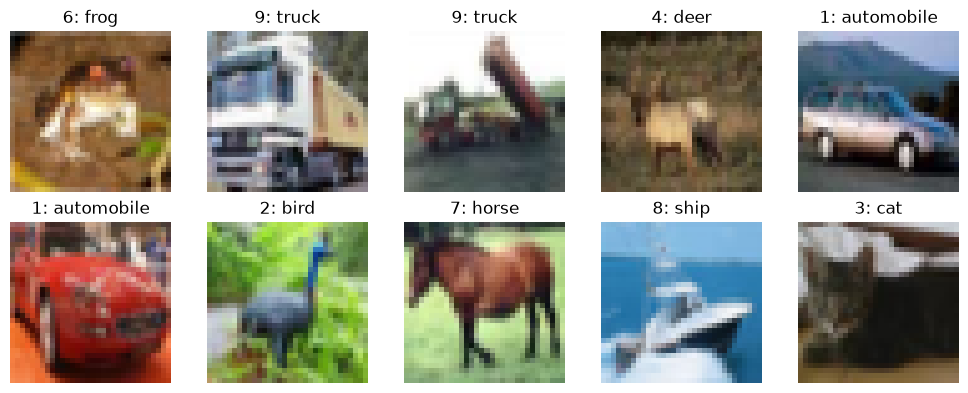

In [1]:
from torchvision.datasets import CIFAR10
import numpy as np
import matplotlib.pyplot as plt

train_dataset = CIFAR10(root="./data", train=True, download=True)
test_dataset = CIFAR10(root="./data", train=False, download=True)

print("Тренировочных примеров:", len(train_dataset))
print("Тестовых примеров:", len(test_dataset))

image, label = train_dataset[0]
img_np = np.array(image)

print("Форма одного изображения (H, W, C):", img_np.shape)
print("Тип dtype одного изображения:", img_np.dtype)
print("Тип type одной метки:", type(label), "значение:", label)
print("Классы:", train_dataset.classes)
print("Количество классов:", len(train_dataset.classes))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    img, y = train_dataset[i]
    ax.imshow(img)
    ax.set_title(f"{y}: {train_dataset.classes[y]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

2. Предобработка данных:
   - Считаем среднее и стандартное отклонение отдельно по каналам по сырому train
   - Train: делаем аугментацию при помощи комбинации случайных обрезки и отражения. Затем переводим в тензор и нормализуем с использованием вычисленных среднего и стандартного отклонения
   - Test: только переводим в тензор и нормализуем
   - Метки остались int. Их примет в таком виде функция для вычисления кросс-энтропии

In [2]:
from torchvision.datasets import CIFAR10
from torchvision import transforms

# Сырой train только для статистики, transform=None — картинки не трогаем.
cifar_train_raw = CIFAR10(root="./data", train=True, download=False, transform=None)

mean_not_normed = cifar_train_raw.data.mean(axis=(0, 1, 2))# R, G, B, диапазон 0..255
std_not_normed = cifar_train_raw.data.std(axis=(0, 1, 2))

mean_normed = mean_not_normed / 255.0
std_normed = std_not_normed / 255.0

print("средние (R, G, B):", mean_normed)
print("std  (R, G, B):", std_normed)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),# PIL, до ToTensor, случайная обрезка
    transforms.RandomHorizontalFlip(),# случайное отражение      
    transforms.ToTensor(),# [0, 1], (C, H, W)
    transforms.Normalize(mean=mean_normed, std=std_normed),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_normed, std=std_normed),# те же числа, что ранее
])

train_dataset = CIFAR10(root="./data", train=True, download=False, transform=train_transform)
test_dataset = CIFAR10(root="./data", train=False, download=False, transform=test_transform)

x, y = train_dataset[0]
print("тензор изображения:", tuple(x.shape), x.dtype)
print("min/max после Normalize:", float(x.min()), float(x.max()))
print("метка:", y, type(y))

средние (R, G, B): [0.49139968 0.48215841 0.44653091]
std  (R, G, B): [0.24703223 0.24348513 0.26158784]
тензор изображения: (3, 32, 32) torch.float32
min/max после Normalize: -1.9892128705978394 2.0945773124694824
метка: 6 <class 'int'>


Пишем загрузчик данных DataLoader. Собираем наборы обучающих и тестовых данных в батчи размера BATCH_SIZE.

In [3]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32
# Делаем перемешивание в батче во избежание корреляций при обучении
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0) 
# При тестировании порядок не важен
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader)) # Для доступа используем итератор
print("Изображения батча:", tuple(images.shape), images.dtype)
print("Метки батча:", tuple(labels.shape), labels.dtype)
print("Тренировочные батчи:", len(train_loader), "Тестовые батчи:", len(test_loader))

Изображения батча: (32, 3, 32, 32) torch.float32
Метки батча: (32,) torch.int64
Тренировочные батчи: 1563 Тестовые батчи: 313


3. Архитектура нейросети

In [4]:
import torch
import torch.nn as nn

class MiniVGG(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # 3x32x32 -> 32x16x16
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True), # преборазование в исходном тензоре
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        # 32x16x16 -> 64x8x8
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        # 64x8x8 -> 128x4x4
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(256, num_classes),  # 10 логитов, без Softmax -- потому что наш лосс сам его считает из сырых логитов и меток классов
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.classifier(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MiniVGG().to(device)

images, labels = next(iter(train_loader))
logits = model(images.to(device))

print("device:", device)
print("logits:", tuple(logits.shape), logits.dtype)
print("params:", sum(p.numel() for p in model.parameters()))

device: cuda
logits: (32, 10) torch.float32
params: 815018


In [5]:
from torchinfo import summary

summary(
    model,
    input_size=(1, 3, 32, 32),
    col_names=("input_size", "output_size", "num_params"),
    depth=3,
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
MiniVGG                                  [1, 3, 32, 32]            [1, 10]                   --
├─Sequential: 1-1                        [1, 3, 32, 32]            [1, 32, 16, 16]           --
│    └─Conv2d: 2-1                       [1, 3, 32, 32]            [1, 32, 32, 32]           896
│    └─BatchNorm2d: 2-2                  [1, 32, 32, 32]           [1, 32, 32, 32]           64
│    └─ReLU: 2-3                         [1, 32, 32, 32]           [1, 32, 32, 32]           --
│    └─Conv2d: 2-4                       [1, 32, 32, 32]           [1, 32, 32, 32]           9,248
│    └─BatchNorm2d: 2-5                  [1, 32, 32, 32]           [1, 32, 32, 32]           64
│    └─ReLU: 2-6                         [1, 32, 32, 32]           [1, 32, 32, 32]           --
│    └─MaxPool2d: 2-7                    [1, 32, 32, 32]           [1, 32, 16, 16]           --
├─Sequential: 1-2              

4. Лосс и оптимизатор

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=5e-4,
)

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

logits = model(images)
loss = criterion(logits, labels)
print("Тестовый запуск")
print("loss:", float(loss), loss.shape, loss.dtype)
print("optimizer:", type(optimizer).__name__, "lr=", optimizer.param_groups[0]["lr"])

Тестовый запуск
loss: 2.4024064540863037 torch.Size([]) torch.float32
optimizer: SGD lr= 0.01


5. Обучение. После $20$ и $30$ эпох уменьшаем в $10$ раз скорость обучения для стабилизации.

In [7]:
from torch.utils.tensorboard import SummaryWriter

EPOCHS = 40
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=[20, 30], gamma=0.1
)
writer = SummaryWriter("runs/minivgg_aug")

def run_epoch(loader, train: bool):
    model.train(train)
    total_loss, correct, total = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()

    with ctx:
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if train:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if train:
                loss.backward()
                optimizer.step()

            bs = labels.size(0)
            total_loss += loss.item() * bs
            correct += (logits.argmax(1) == labels).sum().item()
            total += bs

    return total_loss / total, correct / total

history = {
    "train_loss": [], "train_acc": [], "train_err": [],
    "test_loss": [], "test_acc": [], "test_err": [],
}

for epoch in range(1, EPOCHS + 1):
    lr = optimizer.param_groups[0]["lr"]
    train_loss, train_acc = run_epoch(train_loader, train=True)
    test_loss, test_acc = run_epoch(test_loader, train=False)
    train_err, test_err = 1 - train_acc, 1 - test_acc

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["train_err"].append(train_err)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)
    history["test_err"].append(test_err)

    print(
        f"Epoch {epoch:02d}/{EPOCHS}  lr={lr:.4f}  "
        f"train error={train_err:.3f} acc={train_acc:.3f}"
    )
    scheduler.step()

print("\n=== test после обучения ===")
print(
    f"error={history['test_err'][-1]:.3f}  "
    f"acc={history['test_acc'][-1]:.3f}"
)

writer.close()
print("логи: runs/minivgg_aug")

Epoch 01/40  lr=0.0100  train error=0.655 acc=0.345
Epoch 02/40  lr=0.0100  train error=0.453 acc=0.547
Epoch 03/40  lr=0.0100  train error=0.351 acc=0.649
Epoch 04/40  lr=0.0100  train error=0.293 acc=0.707
Epoch 05/40  lr=0.0100  train error=0.255 acc=0.745
Epoch 06/40  lr=0.0100  train error=0.234 acc=0.766
Epoch 07/40  lr=0.0100  train error=0.217 acc=0.783
Epoch 08/40  lr=0.0100  train error=0.204 acc=0.796
Epoch 09/40  lr=0.0100  train error=0.194 acc=0.806
Epoch 10/40  lr=0.0100  train error=0.186 acc=0.814
Epoch 11/40  lr=0.0100  train error=0.184 acc=0.816
Epoch 12/40  lr=0.0100  train error=0.171 acc=0.829
Epoch 13/40  lr=0.0100  train error=0.170 acc=0.830
Epoch 14/40  lr=0.0100  train error=0.163 acc=0.837
Epoch 15/40  lr=0.0100  train error=0.160 acc=0.840
Epoch 16/40  lr=0.0100  train error=0.158 acc=0.842
Epoch 17/40  lr=0.0100  train error=0.155 acc=0.845
Epoch 18/40  lr=0.0100  train error=0.152 acc=0.848
Epoch 19/40  lr=0.0100  train error=0.148 acc=0.852
Epoch 20/40 

=== test после обучения ===
error=0.102  acc=0.898


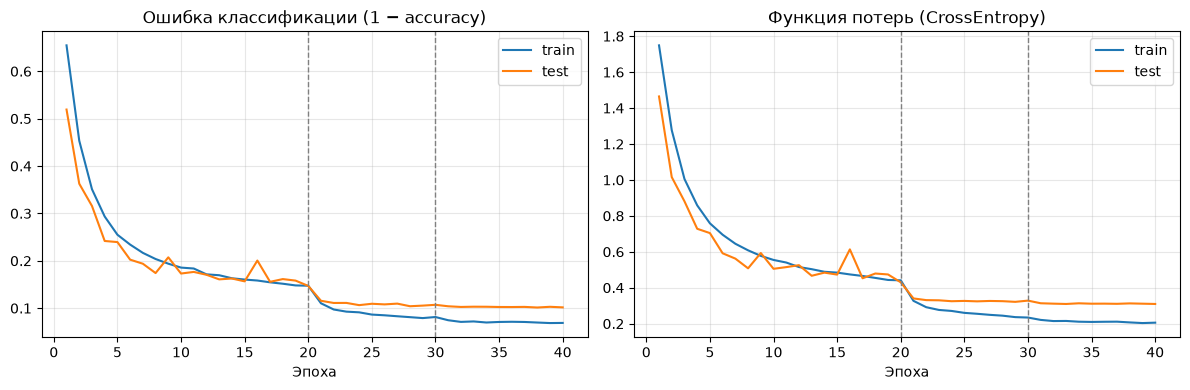

In [8]:
import matplotlib.pyplot as plt

epochs = range(1, EPOCHS + 1)

print("=== test после обучения ===")
print(
    f"error={history['test_err'][-1]:.3f}  "
    f"acc={history['test_acc'][-1]:.3f}"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_err"], label="train")
axes[0].plot(epochs, history["test_err"], label="test")
axes[0].axvline(20, color="gray", ls="--", lw=1)
axes[0].axvline(30, color="gray", ls="--", lw=1)
axes[0].set_title("Ошибка классификации (1 − accuracy)")
axes[0].set_xlabel("Эпоха")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, history["train_loss"], label="train")
axes[1].plot(epochs, history["test_loss"], label="test")
axes[1].axvline(20, color="gray", ls="--", lw=1)
axes[1].axvline(30, color="gray", ls="--", lw=1)
axes[1].set_title("Функция потерь (CrossEntropy)")
axes[1].set_xlabel("Эпоха")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()